In [11]:
import os
import glob
import json
import re
import zipfile
from datetime import datetime
from urllib.request import urlretrieve

import numpy as np
import rasterio
import torch
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from rasterio.transform import Affine
from rasterio.vrt import WarpedVRT
from rasterio.windows import Window

# Set the model cache before importing OLMoEarth.
os.environ['HF_HOME'] = os.path.join(os.environ['SCRATCH'],'huggingface')

from olmoearth_pretrain.data.constants import Modality
from olmoearth_pretrain.data.normalize import Normalizer,Strategy
from olmoearth_pretrain.datatypes import MaskedOlmoEarthSample,MaskValue
from olmoearth_pretrain.model_loader import ModelID,load_model_from_id

plt.rcParams.update({
    'savefig.dpi':900,
    'savefig.bbox':'tight',
    'savefig.pad_inches':0.02,
    'font.size':9,
    'axes.labelsize':9,
    'axes.titlesize':9,
    'xtick.labelsize':9,
    'ytick.labelsize':9,
    'legend.fontsize':9,
    'figure.titlesize':9,
    'xtick.minor.visible':False,
    'ytick.minor.visible':False})

In [2]:
PROJECTDIR = os.path.join(os.environ['SCRATCH'],'olmoearth')
DATADIR    = os.path.join(PROJECTDIR,'data')
OUTPUTDIR  = os.path.join(PROJECTDIR,'outputs','seattle')

MODEL      = 'OLMOEARTH_V1_BASE'
CROPSIZE   = 64
PATCHSIZE  = 4
CROPROW    = None
CROPCOL    = None
BANDS      = list(Modality.SENTINEL2_L2A.band_order)

SCENEURL = (
    'https://storage.googleapis.com/'
    'ai2-rslearn-projects-data/artifacts/'
    'example_sentinel2_l2a_scene_of_seattle.zip')
ZIPFILE   = os.path.join(DATADIR,'example_sentinel2_l2a_scene_of_seattle.zip')
ARRAYFILE = os.path.join(OUTPUTDIR,'embeddings.npy')
RASTERFILE = os.path.join(OUTPUTDIR,'embeddings.tif')
METAFILE  = os.path.join(OUTPUTDIR,'metadata.json')
FIGURE    = os.path.join(OUTPUTDIR,'rgb_and_embedding_pc1.png')

os.makedirs(DATADIR,exist_ok=True)
os.makedirs(OUTPUTDIR,exist_ok=True)

In [3]:
scenes = sorted(glob.glob(os.path.join(DATADIR,'**','*.SAFE'),recursive=True))

if not scenes:
    if not os.path.isfile(ZIPFILE):
        print('Downloading example imagery...')
        urlretrieve(SCENEURL,ZIPFILE+'.part')
        os.replace(ZIPFILE+'.part',ZIPFILE)

    print('Extracting imagery...')
    with zipfile.ZipFile(ZIPFILE) as archive:
        archive.extractall(DATADIR)

    scenes = sorted(glob.glob(os.path.join(DATADIR,'**','*.SAFE'),recursive=True))

if len(scenes) != 1:
    raise ValueError(f'Expected one .SAFE scene, found {len(scenes)}.')

scene = scenes[0]
match = re.search(r'MSIL2A_(\d{8})T',os.path.basename(scene))
if match is None:
    raise ValueError('Could not determine the acquisition date.')

date = datetime.strptime(match.group(1),'%Y%m%d')

print(os.path.basename(scene))
print(f'Acquisition date: {date:%Y-%m-%d}')

S2C_MSIL2A_20250822T190931_N0511_R056_T10TET_20250822T235612.SAFE
Acquisition date: 2025-08-22


In [4]:
granules = sorted(
    path for path in glob.glob(os.path.join(scene,'GRANULE','*'))
    if os.path.isdir(path))

if len(granules) != 1:
    raise ValueError('Select a single granule before reading the scene.')

bandpaths = []
for band in BANDS:
    matches = sorted(glob.glob(
        os.path.join(granules[0],'IMG_DATA','*',f'*_{band}_*.jp2')))
    if not matches:
        raise FileNotFoundError(f'Could not find band {band}.')
    bandpaths.append(matches[0])

with rasterio.open(bandpaths[0]) as src:
    row = (src.height-CROPSIZE)//2 if CROPROW is None else CROPROW
    col = (src.width-CROPSIZE)//2 if CROPCOL is None else CROPCOL

    if row < 0 or col < 0 or row+CROPSIZE > src.height or col+CROPSIZE > src.width:
        raise ValueError('The requested crop extends outside the scene.')

    window = Window(col,row,CROPSIZE,CROPSIZE)
    transform = src.window_transform(window)
    crs = src.crs

rawimage = np.empty((len(BANDS),CROPSIZE,CROPSIZE),dtype=np.float32)

for i,filepath in enumerate(bandpaths):
    with rasterio.open(filepath) as src:
        with WarpedVRT(
            src,crs=crs,transform=transform,
            width=CROPSIZE,height=CROPSIZE,
            resampling=Resampling.bilinear,
        ) as vrt:
            rawimage[i] = vrt.read(1,out_dtype='float32')

if np.any(rawimage == 0):
    raise ValueError(
        'The crop includes zero/nodata values. '
        'Change CROPROW and CROPCOL, then rerun from this cell.')

print('Image shape:',rawimage.shape)
print('Band order:',BANDS)
print('Crop row, column:',row,col)

Image shape: (12, 64, 64)
Band order: ['B02', 'B03', 'B04', 'B08', 'B05', 'B06', 'B07', 'B8A', 'B11', 'B12', 'B01', 'B09']
Crop row, column: 5458 5458


In [5]:
if not torch.cuda.is_available():
    raise RuntimeError('Open this notebook in a GPU compute session.')

device = torch.device('cuda')

image = rawimage.transpose(1,2,0)[None,:,:,None,:]
normalizer = Normalizer(Strategy.COMPUTED)
image = normalizer.normalize(Modality.SENTINEL2_L2A,image).astype(np.float32)

sample = MaskedOlmoEarthSample(
    sentinel2_l2a=torch.as_tensor(image,dtype=torch.float32,device=device),
    sentinel2_l2a_mask=torch.full(
        (1,CROPSIZE,CROPSIZE,1,Modality.SENTINEL2_L2A.num_band_sets),
        float(MaskValue.ONLINE_ENCODER.value),
        dtype=torch.float32,device=device),
    timestamps=torch.tensor(
        [[[date.day,date.month-1,date.year]]],device=device))

print('Input shape:',image.shape)
print('GPU:',torch.cuda.get_device_name(0))

Input shape: (1, 64, 64, 1, 12)
GPU: NVIDIA A100-PCIE-40GB


In [7]:
model = load_model_from_id(getattr(ModelID,MODEL)).to(device).eval()

with torch.inference_mode():
    output = model.encoder(sample,fast_pass=True,patch_size=PATCHSIZE)
    tokens = output['tokens_and_masks'].sentinel2_l2a
    embeddings = tokens.mean(dim=(3,4))[0].cpu().numpy()

print('Raw token shape:',tuple(tokens.shape))
print('Pooled embedding shape:',embeddings.shape)
print('All values finite:',np.isfinite(embeddings).all())

/pscratch/sd/s/sferrett/uv-python/cpython-3.12.16-linux-x86_64-gnu/lib/python3.12/importlib/__init__.py:90: FutureWarning: The 'helios' package has been renamed to 'olmoearth_pretrain'. Please update your imports; this compatibility shim will be removed in a future release.
  return _bootstrap._gcd_import(name[level:], package, level)


Raw token shape: (1, 16, 16, 1, 3, 768)
Pooled embedding shape: (16, 16, 768)
All values finite: True


In [8]:
indices = [BANDS.index(band) for band in ['B04','B03','B02']]
rgb = np.moveaxis(rawimage[indices],0,-1)

lower = np.percentile(rgb,2,axis=(0,1))
upper = np.percentile(rgb,98,axis=(0,1))
rgb = np.clip((rgb-lower)/np.maximum(upper-lower,1e-6),0,1)

height,width,nfeatures = embeddings.shape
features = embeddings.reshape(-1,nfeatures)
centered = features-features.mean(axis=0,keepdims=True)

u,s,_ = np.linalg.svd(centered,full_matrices=False)
pc1 = (u[:,0]*s[0]).reshape(height,width)

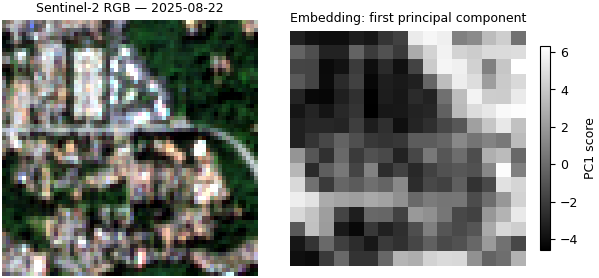

In [9]:
fig,axs = plt.subplots(ncols=2,figsize=(6.5,3))

axs[0].imshow(rgb)
axs[0].set_title(f'Sentinel-2 RGB — {date:%Y-%m-%d}')

im = axs[1].imshow(pc1,cmap='gray',interpolation='nearest')
axs[1].set_title('Embedding: first principal component')
fig.colorbar(im,ax=axs[1],label='PC1 score',shrink=0.8)

for ax in axs:
    ax.set_axis_off()

fig.tight_layout()
fig.savefig(FIGURE)
plt.show()

In [10]:
np.save(ARRAYFILE,embeddings)

embeddingtransform = transform*Affine.scale(PATCHSIZE,PATCHSIZE)

with rasterio.open(
    RASTERFILE,'w',driver='GTiff',
    height=height,width=width,count=nfeatures,
    dtype='float32',crs=crs,
    transform=embeddingtransform,compress='deflate',
) as dst:
    dst.write(np.moveaxis(embeddings,-1,0))

metadata = {
    'scene':os.path.basename(scene),
    'acquisition_date':date.date().isoformat(),
    'model':MODEL,
    'torch_version':torch.__version__,
    'band_order':BANDS,
    'normalization':'Strategy.COMPUTED',
    'crop_row':int(row),
    'crop_col':int(col),
    'crop_size':CROPSIZE,
    'patch_size':PATCHSIZE,
    'pooling':'Mean over time and spectral band groups',
    'embedding_shape':list(embeddings.shape),
    'crs':crs.to_string(),
    'embedding_transform':list(embeddingtransform)[:6],
    'cloud_screening_applied':False}

with open(METAFILE,'w',encoding='utf-8') as f:
    json.dump(metadata,f,indent=2)